Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.
24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Epoch 1/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 36s 413ms/step - accuracy: 0.9545 - loss: 0.1535 - val_accuracy: 0.9900 - val_loss: 0.0493
Epoch 2/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 23s 364ms/step - accuracy: 0.9895 - loss: 0.0465 - val_accuracy: 0.9930 - val_loss: 0.0314
Epoch 3/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 22s 350ms/step - accuracy: 0.9965 - loss: 0.0302 - val_accuracy: 0.9940 - val_loss: 0.0248
Epoch 4/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 22s 355ms/step - accuracy: 0.9945 - loss: 0.0272 - val_accuracy: 0.9960 - val_loss: 0.0215
Epoch 5/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 22s 357ms/step - accuracy: 0.9950 - loss: 0.0217 - val_accuracy: 0.9940 - val_loss: 0.0210
32/32 ━━━━━━━━━━━━━━━━━━━━ 8s 248ms/step - accuracy: 0.9940 - loss: 0.0210
Validation Accuracy: 99.40000176429749 %


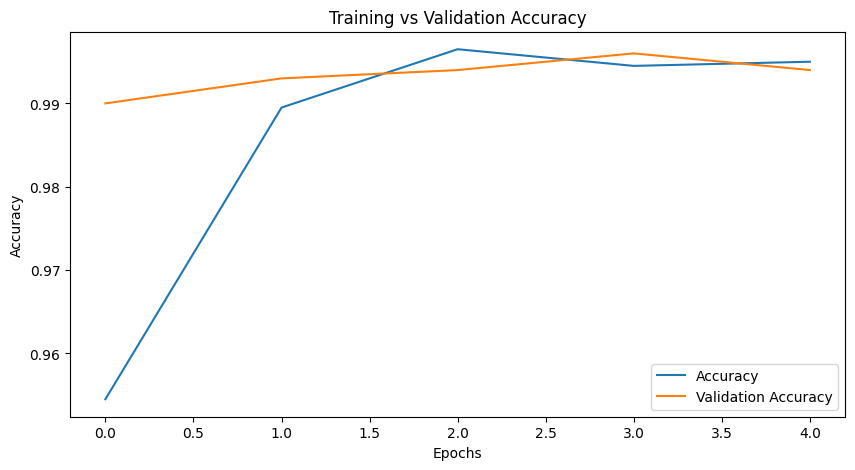

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


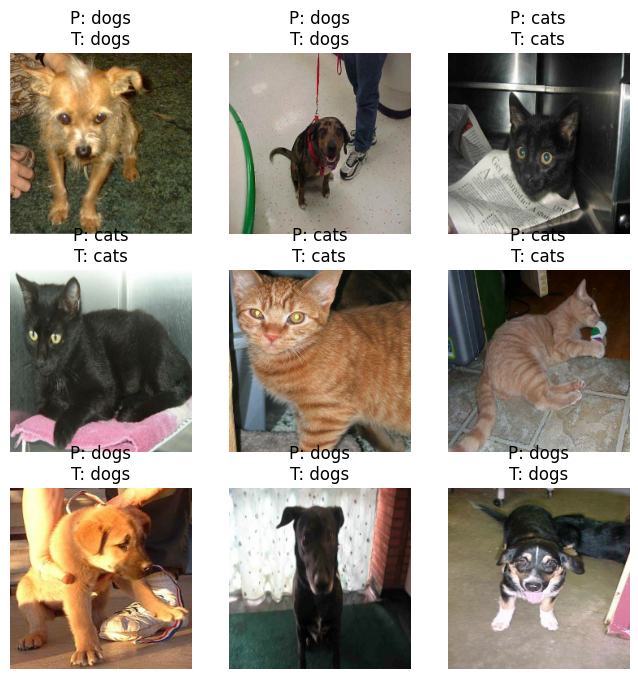

In [1]:

# PRACTICAL 1: CAT AND DOG CLASSIFICATION
# Technique: Transfer Learning using EfficientNetV2B0

# 1. Import libraries
import tensorflow as tf
from tensorflow.keras import layers, Sequential
import matplotlib.pyplot as plt

# 2. Dataset paths
train = r"Downloads/cats_and_dogs_filtered/cats_and_dogs_filtered/train"
val = r"Downloads/cats_and_dogs_filtered/cats_and_dogs_filtered/validation"

# 3. Image size
img_size = (224, 224)

# 4. Load datasets
train_d = tf.keras.utils.image_dataset_from_directory(
    train, image_size=img_size
)

val_d = tf.keras.utils.image_dataset_from_directory(
    val, image_size=img_size
)

# 5. Get class names
names = train_d.class_names

# 6. Optimize datasets
train_d = train_d.cache().shuffle(1000).prefetch(tf.data.AUTOTUNE)

# CHANGE: Use val_d, not train_d
val_d = val_d.cache().prefetch(tf.data.AUTOTUNE)

# 7. Load pre-trained EfficientNetV2B0
base = tf.keras.applications.EfficientNetV2B0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

# 8. Freeze pre-trained model
base.trainable = False

# 9. Create model
model = Sequential([
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(len(names), activation='softmax')
])

# 10. Compile model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 11. Train model
history = model.fit(
    train_d,
    validation_data=val_d,
    epochs=5
)

# 12. Evaluate model
print("Validation Accuracy:",
      model.evaluate(val_d)[1] * 100, "%")

# 13. Plot accuracy graph
plt.figure(figsize=(10, 5))
plt.plot(history.history['accuracy'], label='Accuracy')
plt.plot(history.history['val_accuracy'],
         label='Validation Accuracy')

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# 14. Predict images
for imgs, lbls in val_d.take(1):

    preds = tf.argmax(model.predict(imgs), axis=1)

    plt.figure(figsize=(8, 8))

    for i in range(9):
        plt.subplot(3, 3, i+1)

        plt.imshow(imgs[i].numpy().astype("uint8"))

        plt.title(
            f"P: {names[int(preds[i])]}\n"
            f"T: {names[int(lbls[i])]}"
        )

        plt.axis('off')

    plt.show()
